In [1]:
from helpers import *

mpl.rcParams['font.size'] = 14

In [ ]:

eq_file_index = {
    "WF": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_WF/flow_properties.csv",'o', 'r'),
    "TWF": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TWF/flow_properties.csv",'p', 'orange'),
    "H": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_H/flow_properties.csv",'8', 'b'),
    "TM$_1$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/flow_properties.csv",'v', 'purple'),
    "M": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_M/flow_properties.csv",'d', 'y'),
    "sM$_1$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM1/flow_properties.csv",'s', 'g'),
    "sM$_2$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM2/flow_properties.csv",'^', 'b'),
    "sM$_{3,up}$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM3_up/flow_properties.csv",'>', 'brown'),
    "sM$_{3,low}$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM3_low/flow_properties.csv",'<', 'brown'),
}

po_file_index = {
    "RPO1": "Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/timehistory/timehistory_s*.h5",
}

dns_file_index = {
    "DNS": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/flowproperties/flowproperties_s*.h5",'-', 'gray',
            "Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/snapshots/snapshots_s*.h5"),
}

size of D: (33533,)
min I_dns = 511.3596667045749
shape of t_list: (3000,)
dt: 0.10010771416990366
shape of field_list: (3000, 128, 128)
dt_ratio = 10
max_abs = 1.001892320590105
initial_snap_idx = 1000


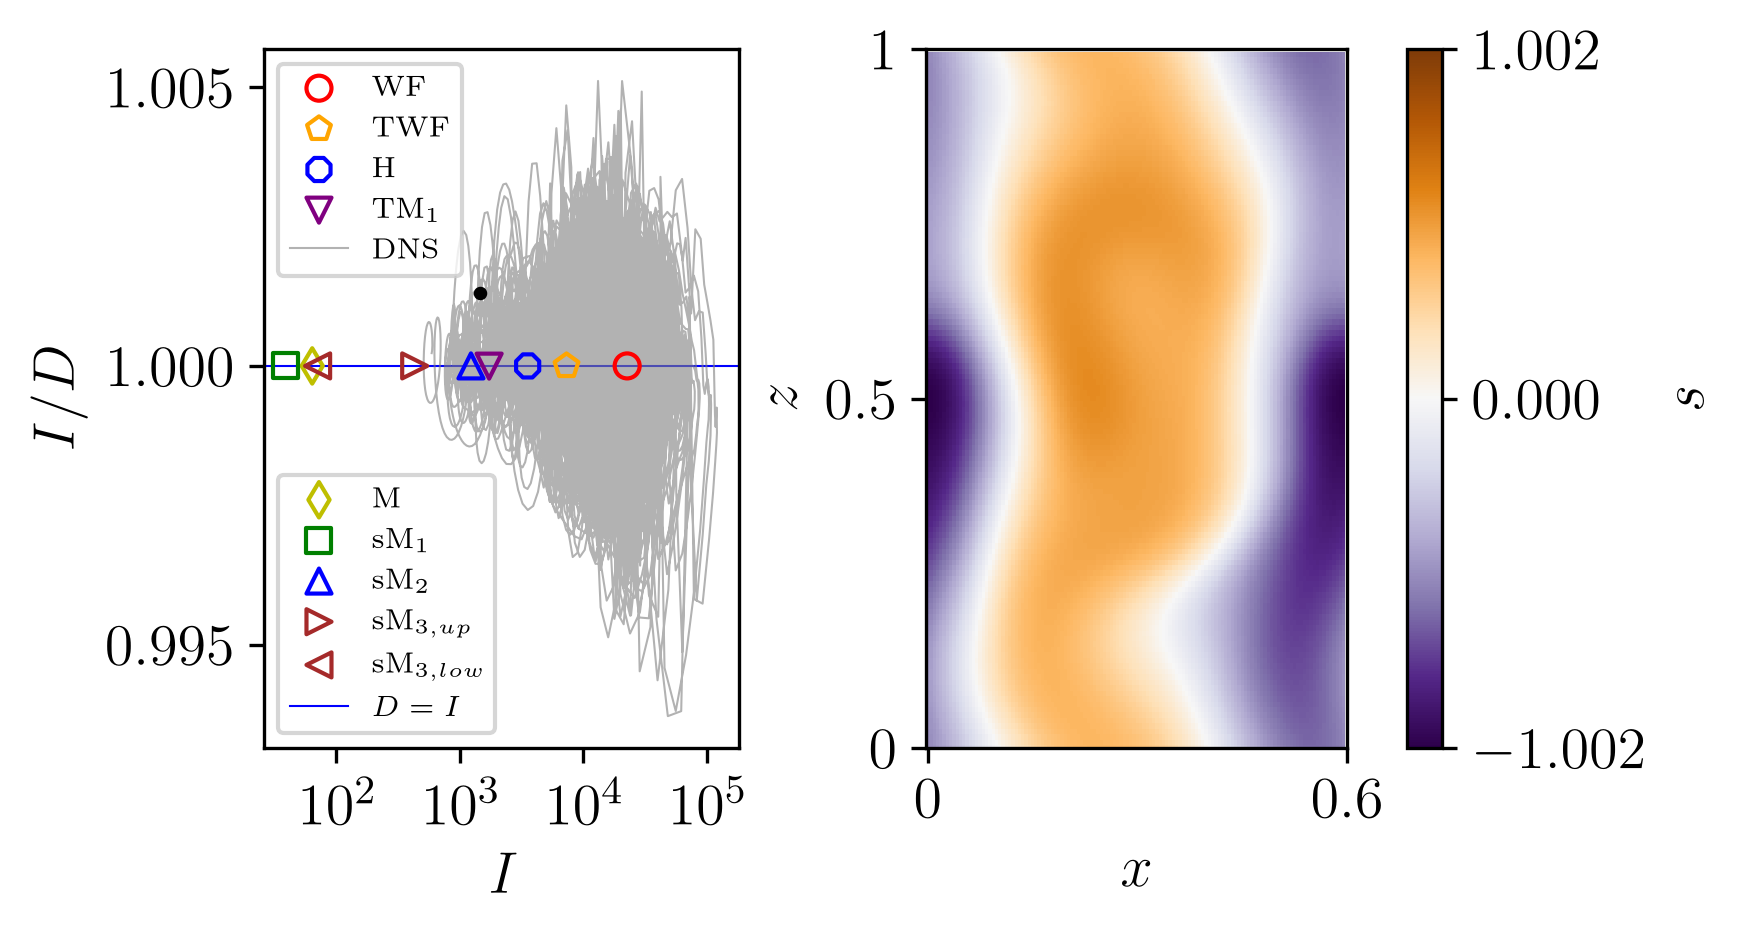

nframes =  2000
Updating frame 0, index 10000, snapshot_idx 1000
Updating frame 0, index 10000, snapshot_idx 1000
Updating frame 1, index 10002, snapshot_idx 1000
Updating frame 2, index 10004, snapshot_idx 1000
Updating frame 3, index 10006, snapshot_idx 1000
Updating frame 4, index 10008, snapshot_idx 1000
Updating frame 5, index 10010, snapshot_idx 1001
Updating frame 6, index 10012, snapshot_idx 1001
Updating frame 7, index 10014, snapshot_idx 1001
Updating frame 8, index 10016, snapshot_idx 1001
Updating frame 9, index 10018, snapshot_idx 1001
Updating frame 10, index 10020, snapshot_idx 1002
Updating frame 11, index 10022, snapshot_idx 1002
Updating frame 12, index 10024, snapshot_idx 1002
Updating frame 13, index 10026, snapshot_idx 1002
Updating frame 14, index 10028, snapshot_idx 1002
Updating frame 15, index 10030, snapshot_idx 1003
Updating frame 16, index 10032, snapshot_idx 1003
Updating frame 17, index 10034, snapshot_idx 1003
Updating frame 18, index 10036, snapshot_idx 

In [3]:
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from matplotlib.animation import FFMpegWriter

# Check if Matplotlib already sees FFmpeg
if not animation.FFMpegWriter.isAvailable():
    try:
        import imageio_ffmpeg

        # Connect imageio-ffmpeg executable to Matplotlib
        plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    except ImportError:
        print("imageio-ffmpeg is not installed. Run: %pip install imageio-ffmpeg")

fig, (ax1,ax2) = plt.subplots(
    1, 2, 
    figsize=(5.7, 3),
    # gridspec_kw={"width_ratios": [2, 3]},
    constrained_layout=True,
    dpi=300
    )

line_eq = []
for eq_name, (file_path, marker, color) in eq_file_index.items():
    D, I = load_energy_eq(file_path)
    sc = ax1.scatter(I,I/D, color=color, marker=marker, label=eq_name, facecolors="None", zorder=2)
    line_eq.append(sc)

line_dns = []
for dns_name, (file_pattern, linestyle, color, snapshots_path) in dns_file_index.items():
    D, I = load_energy_dns(file_pattern)
    print(f"size of D: {np.shape(D)}")
    # Slice the data
    I_dns = I[:30000]
    D_dns = D[:30000]
    line, = ax1.plot(I_dns,I_dns/D_dns, color=color, linestyle=linestyle, linewidth=0.5, label=dns_name, alpha=0.6, zorder=1)
    line_dns.append(line)
    x,z,sa_snapshot_time,sa_snapshots = load_snapshot_dns(snapshots_path)
    sa_snapshot_time = sa_snapshot_time[:3000]
    sa_snapshots = sa_snapshots[:3000]

line_DI = ax1.axline((0, 1), slope=0, linestyle='-', color='b', linewidth=0.5, label=r'$D=I$', zorder=0)
ax1.set_xscale('log')
ax1.set_xticks([1e2, 1e3, 1e4,1e5])
ax1.set_xlabel(r'$I$')
ax1.set_ylabel(r'$I/D$')

# Create FIRST legend
first_legend = ax1.legend(handles=line_eq[:4]+line_dns, loc='upper left', fontsize=7, frameon=True)
ax1.add_artist(first_legend)
# Create SECOND legend (this would normally delete legend #1)
ax1.legend(handles=line_eq[4:]+[line_DI], loc='lower left', fontsize=7, frameon=True)


idx_start = 10000
step = 2
nframes = 2000

print(f"min I_dns = {np.min(I_dns)}")
point = ax1.scatter(I_dns[idx_start],I_dns[idx_start]/D_dns[idx_start], marker='.', color='k', s=20, zorder=1)

########## show time-dependent solution on right panel
print(f"shape of t_list: {np.shape(sa_snapshot_time)}")  
print(f"dt: {sa_snapshot_time[1]-sa_snapshot_time[0]}")  
print(f"shape of field_list: {np.shape(sa_snapshots)}") 

dt_snapshot = 0.1
dt_flowproperties = 0.01
dt_ratio = int(dt_snapshot/dt_flowproperties)
print(f"dt_ratio = {dt_ratio}")

initial_snap_idx = min(int(idx_start / dt_ratio), len(sa_snapshots) - 1)
smin = np.min(sa_snapshots[initial_snap_idx])
smax = np.max(sa_snapshots[initial_snap_idx])
max_abs = max(abs(smin), abs(smax))
print(f"max_abs = {max_abs}")
print(f"initial_snap_idx = {initial_snap_idx}")

X_ax2, Z_ax2 = np.meshgrid(x, z)
# print(sa_snapshots[initial_snap_idx])
surface_sa = ax2.pcolormesh(
    X_ax2, Z_ax2, sa_snapshots[initial_snap_idx].T,
    vmin=-max_abs, vmax=max_abs, shading='auto', cmap = 'PuOr_r')
cbar = fig.colorbar(
    surface_sa, 
    ax=ax2, 
    label='$s$', 
    ticks=np.linspace(-max_abs, max_abs, 3))
ax2.set_xlabel('$x$')
ax2.set_ylabel('$z$')
ax2.set_ylim([0,1])
ax2.set_yticks([0,0.5,1],['0','0.5','1'])
ax2.set_xticks([0,0.6],['0','0.6'])
ax2.set_aspect('equal')
#################

# plt.tight_layout()
plt.show()


print("nframes = ",nframes)

def update(frame):
    index = idx_start + int(frame * step)
    snapshot_idx = min(int(index / dt_ratio), len(sa_snapshots) - 1)
    print(f"Updating frame {frame}, index {index}, snapshot_idx {snapshot_idx}")

    point.set_offsets([I_dns[index],I_dns[index]/D_dns[index]])

    surface_sa.set_array(sa_snapshots[snapshot_idx].T.ravel())
    vmin_curr = np.nanmin(sa_snapshots[snapshot_idx])
    vmax_curr = np.nanmax(sa_snapshots[snapshot_idx])
    max_abs = max(abs(vmin_curr), abs(vmax_curr))
    surface_sa.set_clim(vmin=-max_abs, vmax=max_abs)
    cbar.set_ticks(np.linspace(-max_abs, max_abs, 3))
    cbar.set_ticklabels([f"{t:.2f}" for t in np.linspace(-max_abs, max_abs, 3)])

    return point, surface_sa

ani = FuncAnimation(fig, 
                    update, 
                    frames=nframes,
                    interval=40, 
                    blit=False, 
                    repeat=True)

ani.save('S5.mp4', 
        writer='ffmpeg', 
        fps=48, 
        dpi=300, 
        bitrate=2000)
